# 01 · Análisis exploratorio (EDA): Airbnb en Madrid

## Introducción

Este notebook recorre el análisis exploratorio del proyecto final del Máster en Data Analytics. La pregunta de
fondo es doble: **con qué se asocia el precio por noche** de un anuncio de Airbnb en Madrid y **cómo está
organizada la oferta** (qué se alquila, dónde y quién lo alquila). Antes de cualquier contraste formal conviene
mirar los datos con calma: cómo se distribuye el precio, qué columnas faltan, qué grupos son pequeños y qué
relaciones aparecen a simple vista.

El notebook **no repite la limpieza**. Lee el dataset procesado (`data/processed/listings_limpio.parquet`) y los
resultados (`reports/findings.json`) que genera `python run_pipeline.py`, y llama a las mismas funciones de
`src/` que el pipeline, de modo que las cifras del notebook y las del informe salen del mismo código. Además de
leer resultados, aquí se calculan **operaciones pandas explícitas** (`describe`, `value_counts`,
`groupby().agg`, `crosstab`, `pivot_table`, `merge`) directamente sobre el DataFrame, para que se vea cómo se
obtienen las tablas.

Una advertencia de lectura que vale para todo el notebook: los datos son **observacionales**. Cuando decimos que
el precio «se asocia» con algo, no afirmamos que ese algo lo cause. Las interpretaciones que siguen a cada figura
se generan con cifras leídas de `findings.json` o calculadas en la propia celda; ninguna está escrita a mano.

Se genera desde `notebooks/fuentes_py/01_eda.py` con `python scripts/ejecutar_notebooks.py`.

In [1]:
import sys
from pathlib import Path

sys.dont_write_bytecode = True
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from src import analisis, carga, config, formato as fmt, visualizacion as viz

%matplotlib inline
viz.configurar_estilo()
plt.rcParams["figure.dpi"] = 72  # imágenes incrustadas ligeras (las figuras del informe se guardan a 150 dpi)
pd.set_option("display.max_columns", 30)

df = pd.read_parquet(config.RUTA_PARQUET)
with open(config.RUTA_FINDINGS, encoding="utf-8") as f:
    findings = json.load(f)
with open(config.RUTA_CALIDAD, encoding="utf-8") as f:
    calidad = json.load(f)
D, E = findings["descriptivo"], findings["estadistica"]


def lectura(texto: str) -> None:
    """Muestra una interpretación en Markdown (las cifras van dentro del f-string, nunca a mano)."""
    display(Markdown(texto))


print(f"Dataset procesado: {fmt.n0(df.shape[0])} filas × {fmt.n0(df.shape[1])} columnas")

Dataset procesado: 23.109 filas × 112 columnas


## 1. Datos y requisitos mínimos

El primer paso es comprobar que el conjunto de datos cumple los requisitos del proyecto: un volumen suficiente
de filas y columnas y variedad de tipos de variable (numéricas, categóricas, fechas, texto y coordenadas). La
clasificación por tipo se hace por código en `src/calidad.py` sobre el fichero original, no a ojo.

In [2]:
meta, dataset = findings["meta"], findings["dataset"]
print("Snapshot (fecha de la URL):", meta["fecha_snapshot_url"])
print("Fechas de scrape (last_scraped):", meta["last_scraped_min"][:10], "→", meta["last_scraped_max"][:10])
print("Licencia:", dataset["licencia"]["nombre"], "| verificada en la página:", dataset["licencia"]["verificada_en_pagina"])
tipos = pd.Series(dataset["tipos_raw"], name="columnas").sort_values(ascending=False)
tipos.to_frame().assign(pct=lambda t: (t["columnas"] / t["columnas"].sum() * 100).round(1))

Snapshot (fecha de la URL): 2026-09-17
Fechas de scrape (last_scraped): 2026-09-19 → 2026-09-22
Licencia: Creative Commons Attribution 4.0 International (CC BY 4.0) | verificada en la página: True


,columnas,pct
numerico,54,60.0
identificador,10,11.1
texto,10,11.1
fecha,6,6.7
booleano,4,4.4
categorico,4,4.4
geoespacial,2,2.2


In [3]:
lectura(f"**Lectura.** El fichero original tiene {fmt.n0(dataset['filas_raw'])} anuncios y "
        f"{fmt.n0(dataset['columnas_raw'])} columnas; la tabla anterior suma exactamente "
        f"{fmt.n0(tipos.sum())} columnas repartidas en {len(tipos)} tipos lógicos, entre ellos "
        f"{fmt.n0(dataset['tipos_raw']['identificador'])} identificadores. Predominan las numéricas "
        f"({fmt.n0(dataset['tipos_raw']['numerico'])}), lo esperable en un scrape con muchas métricas de "
        "disponibilidad y reseñas.")

**Lectura.** El fichero original tiene 23.109 anuncios y 90 columnas; la tabla anterior suma exactamente 90 columnas repartidas en 7 tipos lógicos, entre ellos 10 identificadores. Predominan las numéricas (54), lo esperable en un scrape con muchas métricas de disponibilidad y reseñas.

## 2. Calidad de datos antes y después de limpiar

La limpieza sigue un orden documentado: perfilar, convertir tipos, derivar variables, eliminar columnas y aplicar
reglas de calidad. Cada regla registra cuántas filas afecta. Comparar el perfil «antes» y «después» permite ver
que la limpieza no ha perdido filas sin contabilizarlas y que los nulos que quedan tienen una decisión explícita
(conservar, imputar con indicador o eliminar la columna).

In [4]:
resumen = pd.DataFrame({
    "antes": {k: calidad["antes"][k] for k in ("filas", "columnas", "nulos_total", "pct_nulos_total", "columnas_con_nulos")},
    "después": {k: calidad["despues"][k] for k in ("filas", "columnas", "nulos_total", "pct_nulos_total", "columnas_con_nulos")},
})
resumen

,antes,después
filas,23109.000000,23109.000000
columnas,90.000000,112.000000
nulos_total,425829.000000,117013.000000
pct_nulos_total,20.474418,4.521004
columnas_con_nulos,46.000000,33.000000


In [5]:
pd.Series(calidad["reglas"], name="filas afectadas").to_frame()

,filas afectadas
precio_nulo_o_no_positivo (precio_valido=False),4324
precio negativo (precio_valido=False),0
"outlier_precio (flag, no se borra)",609
minimum_nights > 365 (flag),8
minimum_nights >= 30 (flag larga estancia),3151
coordenadas fuera del bbox o nulas (excluidas de mapa y distancia),0
duplicados por id (eliminados),0
bedrooms imputado con mediana por grupo,12
beds imputado con mediana por grupo,574


In [6]:
pd.DataFrame(calidad["politica_nulos"])[["columna", "nulos", "decision"]].head(20)

,columna,nulos,decision
0,bathrooms,19,conservar NaN
1,bedrooms,0,"imputar mediana por (room_type, accommodates);..."
2,beds,0,"imputar mediana por (room_type, accommodates);..."
3,price,4324,conservar NaN; precio_valido=False
4,price_quote_checkin_date,3568,conservar NaN
5,price_quote_checkout_date,3568,conservar NaN
6,price_quote_total_price,4936,conservar NaN
7,price_quote_price_per_night,4936,conservar NaN
8,minimum_nights,1729,conservar NaN
9,maximum_nights,1729,conservar NaN


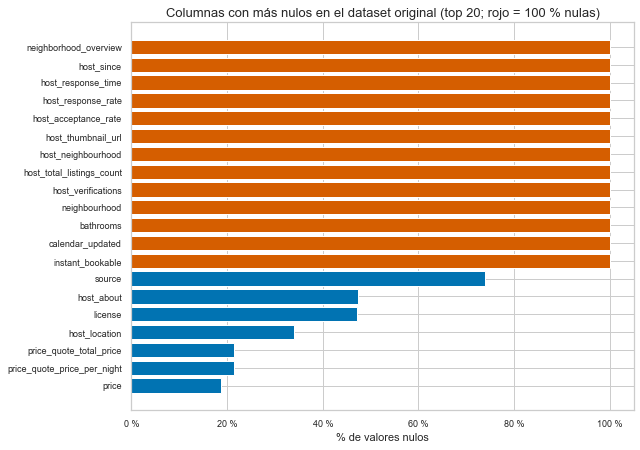

In [7]:
perfil_antes = {"nulos_por_columna_pct": (carga.leer_listings().isna().mean() * 100).to_dict()}
viz.fig_calidad_nulos(perfil_antes);

In [8]:
nulos = pd.Series(perfil_antes["nulos_por_columna_pct"])
lectura(f"**Lectura.** {fmt.n0((nulos == 100).sum())} columnas vienen completamente vacías en este snapshot "
        f"(en rojo) y se eliminan con su motivo. El precio falta en el {fmt.pct1(findings['limpieza']['precio']['pct_nulo'])} "
        f"de los anuncios, y el {fmt.pct1(findings['limpieza']['precio']['pct_nulos_sin_disponibilidad'])} de esos "
        "nulos corresponde a anuncios sin ningún día disponible: los nulos no son aleatorios, por eso el precio no "
        "se imputa y el análisis describe solo la oferta reservable.")

**Lectura.** 13 columnas vienen completamente vacías en este snapshot (en rojo) y se eliminan con su motivo. El precio falta en el 18,7 % de los anuncios, y el 75,6 % de esos nulos corresponde a anuncios sin ningún día disponible: los nulos no son aleatorios, por eso el precio no se imputa y el análisis describe solo la oferta reservable.

## 3. Qué es exactamente el precio

Antes de describir el precio hay que saber qué mide. En Inside Airbnb, `price` es el precio por noche de una
**cotización concreta**: Airbnb calcula cuánto costaría una estancia en unas fechas determinadas (normalmente la
primera ventana reservable, con la duración mínima del anuncio). Ese precio ya lleva aplicados los descuentos
(semanal, mensual, de última hora) y no incluye tasas. Las cifras siguientes se calculan en la limpieza a partir
del JSON `price_quote_raw`.

In [9]:
pn = findings["precio_naturaleza"]
pd.Series({k: v for k, v in pn.items() if k != "partidas_descuento"}, name="valor").to_frame()

,valor
checkin_min,2026-09-19T00:00:00
checkin_max,2027-09-18T00:00:00
n_ambos,18173
pct_precio_igual_cotizacion,100.0
n_cotizaciones_con_precio,18785
n_con_descuento,3812
pct_con_descuento,20.292787
mediana_pct_descuento,9.868854
n_tarifa_mensual,2646
pct_tarifa_mensual,14.085707


In [10]:
lectura(f"**Lectura.** El {fmt.pct1(pn['pct_con_descuento'])} de las cotizaciones con precio incluye algún "
        f"descuento (mediana {fmt.pct1(pn['mediana_pct_descuento'])} del subtotal). La estancia cotizada coincide "
        f"con la estancia mínima en el {fmt.pct1(pn['pct_noches_igual_minimo'])} de los casos, y entre los anuncios "
        f"con estancia mínima de {config.MIN_NIGHTS_LARGA_ESTANCIA} noches o más el "
        f"{fmt.pct1(pn['pct_mensual_entre_min30'])} usa tarifa mensual. Es decir: el «precio por noche» mezcla "
        "tarifas de estancia corta con tarifas mensuales repartidas, algo que habrá que controlar.")

**Lectura.** El 20,3 % de las cotizaciones con precio incluye algún descuento (mediana 9,9 % del subtotal). La estancia cotizada coincide con la estancia mínima en el 75,0 % de los casos, y entre los anuncios con estancia mínima de 30 noches o más el 88,9 % usa tarifa mensual. Es decir: el «precio por noche» mezcla tarifas de estancia corta con tarifas mensuales repartidas, algo que habrá que controlar.

## 4. Distribución del precio

Se describen solo los anuncios con precio publicado (`precio_valido`). La tabla compara el precio, el precio sin
outliers (vallas de Tukey sobre el logaritmo, que se marcan pero no se borran) y el logaritmo del precio, que es
la escala de la regresión. Usamos `describe` de pandas y, para la asimetría y la curtosis, la función del
proyecto; ambas se comprueban contra `findings.json`.

In [11]:
con_precio = df[df["precio_valido"]]
con_precio["price"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(2)

count    18785.00
mean       208.63
std        543.63
min          9.13
5%          38.52
25%         95.45
50%        151.00
75%        224.50
95%        471.50
99%        969.58
max      36883.00
Name: price, dtype: float64

In [12]:
desc = pd.DataFrame({
    "precio": analisis.descriptivos(con_precio["price"]),
    "precio sin outliers": analisis.descriptivos(con_precio.loc[~con_precio["es_outlier_precio"], "price"]),
    "ln(precio)": analisis.descriptivos(con_precio["log_precio"]),
})
# Comprobación: el notebook reproduce las mismas cifras que findings.json.
assert abs(desc.loc["mediana", "precio"] - D["precio"]["mediana"]) < 1e-9
assert abs(desc.loc["asimetria", "precio"] - D["precio"]["asimetria"]) < 1e-9
desc.round(2)

,precio,precio sin outliers,ln(precio)
n,18785.00,18176.00,18785.00
media,208.63,178.61,4.98
mediana,151.00,151.00,5.02
std,543.63,121.25,0.75
q1,95.45,98.00,4.56
q3,224.50,220.92,5.41
iqr,129.05,122.92,0.86
min,9.13,26.47,2.21
max,36883.00,808.00,10.52
p5,38.52,43.77,3.65


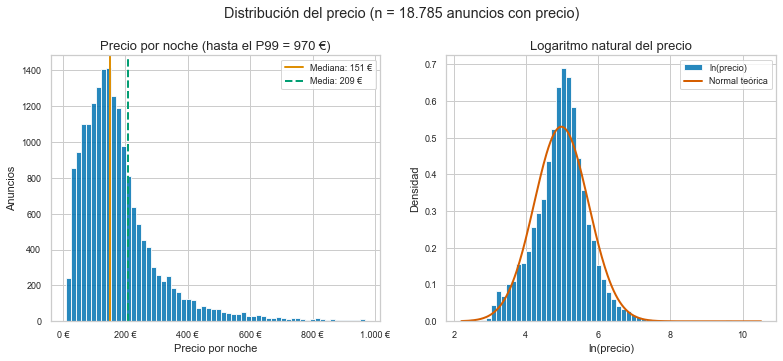

In [13]:
viz.fig_distribucion_precio(df);

In [14]:
lectura(f"**Lectura.** La mediana es {fmt.eur2(desc.loc['mediana', 'precio'])} y la media "
        f"{fmt.eur2(desc.loc['media', 'precio'])}: la media queda por encima porque la cola derecha es muy larga "
        f"(asimetría {fmt.n2(desc.loc['asimetria', 'precio'])}, máximo {fmt.eur0(desc.loc['max', 'precio'])}). "
        f"En logaritmo la asimetría baja a {fmt.n2(desc.loc['asimetria', 'ln(precio)'])}, por eso la regresión "
        "trabaja con `ln(precio)` y los contrastes de grupos usan rangos. La mediana es el resumen más honesto del "
        "«precio típico».")

**Lectura.** La mediana es 151,00 € y la media 208,63 €: la media queda por encima porque la cola derecha es muy larga (asimetría 31,54, máximo 36.883 €). En logaritmo la asimetría baja a 0,21, por eso la regresión trabaja con `ln(precio)` y los contrastes de grupos usan rangos. La mediana es el resumen más honesto del «precio típico».

### Sensibilidad: sin estancias mensuales

Como el precio de las estancias de un mes o más suele ser una tarifa mensual repartida, repetimos los
descriptivos sin esos anuncios ni las cotizaciones mensuales. Si las conclusiones descriptivas cambiaran mucho,
habría que separar los dos mercados en todo el análisis.

In [15]:
corta = con_precio[analisis.mascara_sin_mensuales(con_precio)]
comparacion = pd.DataFrame({"todos": con_precio["price"].describe(), "sin estancias mensuales": corta["price"].describe()})
comparacion.round(2)

,todos,sin estancias mensuales
count,18785.00,15880.00
mean,208.63,225.21
std,543.63,585.03
min,9.13,9.13
25%,95.45,107.64
50%,151.00,161.78
75%,224.50,238.05
max,36883.00,36883.00


In [16]:
lectura(f"**Lectura.** Al quitar {fmt.n0(len(con_precio) - len(corta))} anuncios de estancia mensual, la mediana "
        f"pasa de {fmt.eur2(con_precio['price'].median())} a {fmt.eur2(corta['price'].median())}. Los precios de "
        "estancia corta son más altos por noche, como cabía esperar; el dashboard excluye por defecto ese mercado.")

**Lectura.** Al quitar 2.905 anuncios de estancia mensual, la mediana pasa de 151,00 € a 161,78 €. Los precios de estancia corta son más altos por noche, como cabía esperar; el dashboard excluye por defecto ese mercado.

## 5. Otras variables clave

Capacidad, estancia mínima, disponibilidad, reseñas y valoración. Las variables de conteo suelen ser asimétricas y
con valores extremos (estancias mínimas de más de un año, anuncios con cientos de reseñas), lo que vuelve a
aconsejar medianas y rangos intercuartílicos.

In [17]:
pd.DataFrame({c: analisis.descriptivos(df[c]) for c in
              ["accommodates", "minimum_nights", "availability_365", "number_of_reviews", "review_scores_rating"]}).round(2)

,accommodates,minimum_nights,availability_365,number_of_reviews,review_scores_rating
n,23109.00,21380.00,23109.00,23109.00,19294.00
media,3.26,8.87,159.55,65.98,4.64
mediana,3.00,2.00,151.00,22.00,4.75
std,1.93,26.24,136.26,111.76,0.48
q1,2.00,1.00,1.00,2.00,4.55
q3,4.00,5.00,298.00,80.00,4.91
iqr,2.00,4.00,297.00,78.00,0.36
min,1.00,1.00,0.00,0.00,0.00
max,16.00,1125.00,365.00,1600.00,5.00
p5,1.00,1.00,0.00,0.00,4.00


## 6. Precio por tipo de habitación, distrito, barrio y capacidad

Aquí aparecen las primeras operaciones de agregación explícitas. `groupby().agg` calcula n, mediana, media y
cuartiles por grupo; `value_counts` muestra cuántos anuncios hay de cada tipo (incluidos los que no tienen precio).

In [18]:
df["tipo_habitacion"].value_counts().to_frame("anuncios").assign(
    pct=lambda t: (t["anuncios"] / t["anuncios"].sum() * 100).round(1))

,anuncios,pct
tipo_habitacion,,
Alojamiento entero,16182,70.0
Habitación privada,6735,29.1
Habitación compartida,153,0.7
Habitación de hotel,39,0.2


In [19]:
por_tipo = (con_precio.groupby("tipo_habitacion", observed=True)["price"]
            .agg(n="size", mediana="median", media="mean", q1=lambda s: s.quantile(0.25), q3=lambda s: s.quantile(0.75))
            .sort_values("mediana", ascending=False))
assert por_tipo["mediana"].round(6).tolist() == [round(g["mediana"], 6) for g in D["por_tipo"]]
por_tipo.round(2)

,n,mediana,media,q1,q3
tipo_habitacion,,,,,
Alojamiento entero,13561,173.63,234.55,127.5,247.95
Habitación de hotel,29,162.00,174.34,127.0,201.00
Habitación privada,5059,74.00,142.95,47.0,128.00
Habitación compartida,136,27.00,74.81,24.0,40.00


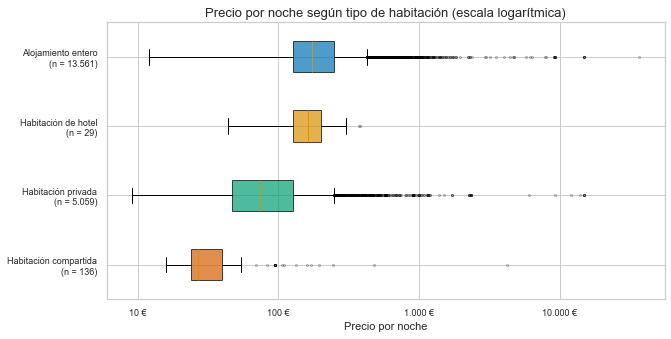

In [20]:
viz.fig_precio_por_tipo(df);

In [21]:
mayor, menor = por_tipo.index[0], por_tipo.index[-1]
lectura(f"**Lectura.** La mediana más alta es la de {mayor.lower()} ({fmt.eur2(por_tipo.loc[mayor, 'mediana'])}, "
        f"n = {fmt.n0(por_tipo.loc[mayor, 'n'])}) y la más baja la de {menor.lower()} "
        f"({fmt.eur2(por_tipo.loc[menor, 'mediana'])}, n = {fmt.n0(por_tipo.loc[menor, 'n'])}). Las cajas casi no se "
        "solapan entre alojamiento entero y habitación privada; los tipos con muy pocos anuncios se describen pero "
        "se agrupan para la inferencia.")

**Lectura.** La mediana más alta es la de alojamiento entero (173,63 €, n = 13.561) y la más baja la de habitación compartida (27,00 €, n = 136). Las cajas casi no se solapan entre alojamiento entero y habitación privada; los tipos con muy pocos anuncios se describen pero se agrupan para la inferencia.

### Distritos

Para los distritos usamos `pivot_table`, que cruza distrito y tipo de habitación con la mediana del precio. Así
se ve si un distrito es caro porque todo es caro o porque tiene más alojamientos enteros. Solo se ordenan los
distritos con al menos `MIN_N_GRUPO` anuncios con precio.

In [22]:
pivote = pd.pivot_table(con_precio, index="neighbourhood_group_cleansed", columns="tipo_habitacion_agrupado",
                        values="price", aggfunc="median", observed=True)
pivote["n"] = con_precio.groupby("neighbourhood_group_cleansed", observed=True).size()
pivote = pivote[pivote["n"] >= config.MIN_N_GRUPO].sort_values("Alojamiento entero", ascending=False)
pivote.round(1)

tipo_habitacion_agrupado,Alojamiento entero,Habitación privada,Otras (compartida + hotel),n
neighbourhood_group_cleansed,,,,
Salamanca,199.4,75.6,95.0,1314
Centro,196.0,107.2,39.0,7866
Chamberí,177.3,70.5,117.5,1159
Retiro,176.9,67.4,NaN,656
Arganzuela,163.4,71.8,32.0,918
Moncloa - Aravaca,163.2,64.6,33.5,503
Chamartín,162.0,98.0,76.0,699
Hortaleza,155.0,77.4,46.0,465
Barajas,152.6,81.0,44.0,148


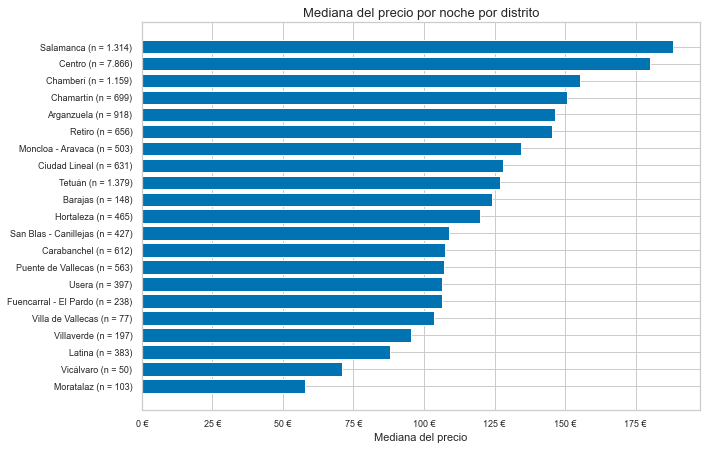

In [23]:
viz.fig_precio_por_distrito(findings);

In [24]:
d0, d1, db = D["por_distrito"][0], D["por_distrito"][1], D["distrito_mas_barato"]
empate = E["top_distritos_empate"]
lectura(f"**Lectura.** {d0['grupo']} ({fmt.eur2(d0['mediana'])}) y {d1['grupo']} ({fmt.eur2(d1['mediana'])}) tienen "
        f"las medianas más altas y {db['grupo']} ({fmt.eur2(db['mediana'])}, n = {fmt.n0(db['n'])}) la más baja. "
        + (f"Entre los dos primeros no hay diferencia estadística (Dunn-Bonferroni p = {fmt.n3(empate['p_ajustado'])}). "
           if empate["empate"] else "")
        + "La tabla cruzada muestra que el orden se mantiene en buena medida dentro del alojamiento entero, así que "
          "no se explica solo por la mezcla de tipos.")

**Lectura.** Salamanca (188,34 €) y Centro (180,00 €) tienen las medianas más altas y Moratalaz (58,00 €, n = 103) la más baja. Entre los dos primeros no hay diferencia estadística (Dunn-Bonferroni p = 1,000). La tabla cruzada muestra que el orden se mantiene en buena medida dentro del alojamiento entero, así que no se explica solo por la mezcla de tipos.

### Barrios y capacidad

Con más de un centenar de barrios, muchos tienen pocos anuncios y su mediana es inestable. La figura solo muestra barrios con al
menos `MIN_N_GRUPO` anuncios con precio y el informe da intervalos bootstrap para los extremos.

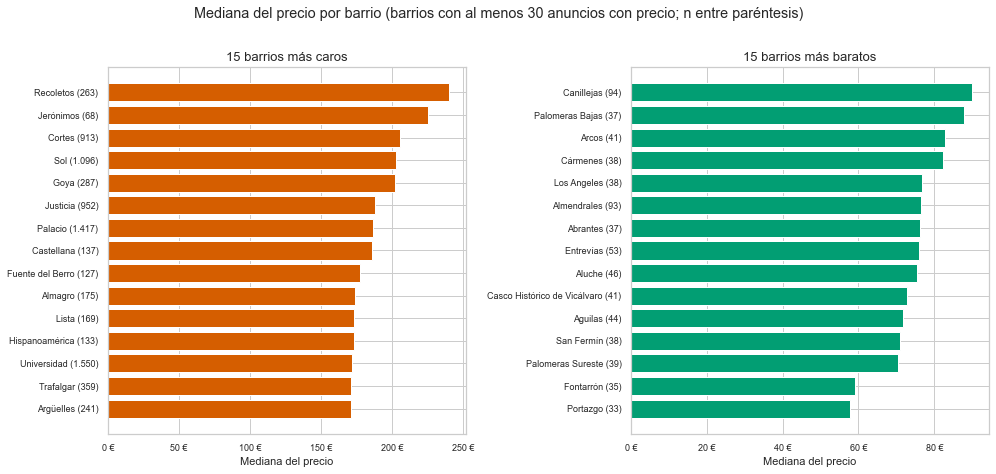

In [25]:
viz.fig_precio_por_barrio(df, config.MIN_N_GRUPO);

In [26]:
b = E["bootstrap"]["barrios_extremos"]
lectura(f"**Lectura.** El barrio de mediana más alta es {b[0]['grupo']} ({fmt.eur2(b[0]['mediana'])}, n = "
        f"{fmt.n0(b[0]['n'])}; IC 95 % por anfitrión {fmt.eur0(b[0]['ic_inf_cluster'])}–{fmt.eur0(b[0]['ic_sup_cluster'])}) "
        f"y el de mediana más baja {b[2]['grupo']} ({fmt.eur2(b[2]['mediana'])}, n = {fmt.n0(b[2]['n'])}). "
        + ("Sus intervalos se solapan con los del segundo barrio de cada lista, así que el orden exacto no es "
           "distinguible." if not (E["bootstrap"]["barrio_top_distinguible"] and E["bootstrap"]["barrio_bottom_distinguible"])
           else "Ambos se distinguen del segundo de su lista."))

**Lectura.** El barrio de mediana más alta es Recoletos (240,00 €, n = 263; IC 95 % por anfitrión 204 €–287 €) y el de mediana más baja Portazgo (57,71 €, n = 33). Sus intervalos se solapan con los del segundo barrio de cada lista, así que el orden exacto no es distinguible.

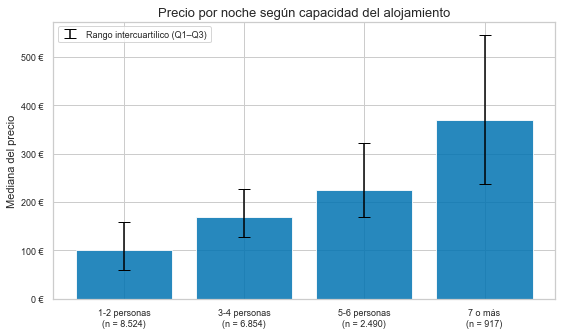

In [27]:
viz.fig_precio_por_capacidad(findings);

In [28]:
cap = pd.DataFrame(D["por_capacidad"]).set_index("grupo")
lectura(f"**Lectura.** La mediana sube con la capacidad, desde {fmt.eur2(cap['mediana'].iloc[0])} en "
        f"{cap.index[0]} hasta {fmt.eur2(cap['mediana'].iloc[-1])} en {cap.index[-1]}. La capacidad es, además, la "
        "variable más correlacionada con el precio (sección 10).")

**Lectura.** La mediana sube con la capacidad, desde 101,20 € en 1-2 personas hasta 368,85 € en 7 o más. La capacidad es, además, la variable más correlacionada con el precio (sección 10).

### Fecha de la cotización

Como cada anuncio se cotiza para fechas distintas, el precio mezcla temporadas. La tabla agrupa por mes de
entrada de la cotización.

In [29]:
por_mes = con_precio.groupby("mes_cotizacion")["price"].agg(n="size", mediana="median")
por_mes.round(2)

,n,mediana
mes_cotizacion,,
2026-09,9623,159.00
2026-10,4800,174.00
2026-11,1813,128.50
2026-12,972,87.54
2027-01,588,94.01
2027-02,208,94.89
2027-03,103,103.30
2027-04,83,108.27
2027-05,180,98.91


In [30]:
lectura(f"**Lectura.** La mayoría de cotizaciones se concentra en los primeros meses "
        f"({fmt.pct1(D['mes_cotizacion']['pct_primeros_dos_meses'])} en los dos primeros). Las medianas mensuales "
        f"van de {fmt.eur2(D['mes_cotizacion']['mes_mediana_min']['mediana'])} a "
        f"{fmt.eur2(D['mes_cotizacion']['mes_mediana_max']['mediana'])} entre los meses con suficientes anuncios; "
        "por eso los modelos del notebook 02 incluyen el mes como control.")

**Lectura.** La mayoría de cotizaciones se concentra en los primeros meses (76,8 % en los dos primeros). Las medianas mensuales van de 74,50 € a 174,00 € entre los meses con suficientes anuncios; por eso los modelos del notebook 02 incluyen el mes como control.

## 7. Composición de anfitriones

Un mismo anfitrión puede tener muchos anuncios. Con `groupby("host_id").size()` contamos anuncios por anfitrión y
con `merge` añadimos ese recuento a cada anuncio para comparar el precio según el tamaño de la cartera. Tener
varios anuncios mide concentración de la oferta, no prueba gestión profesional.

In [31]:
por_host = df.groupby("host_id").size().rename("anuncios_del_host").reset_index()
por_host["anuncios_del_host"].describe().round(2)

count    8704.00
mean        2.65
std        11.05
min         1.00
25%         1.00
50%         1.00
75%         2.00
max       469.00
Name: anuncios_del_host, dtype: float64

In [32]:
con_host = con_precio.merge(por_host, on="host_id", how="left", validate="many_to_one")
con_host.groupby("segmento_host", observed=True).agg(
    anuncios=("price", "size"), mediana=("price", "median"), pct_superhost=("host_is_superhost", "mean")).round(3)

,anuncios,mediana,pct_superhost
segmento_host,,,
1 anuncio,4199,141.06,0.334
2-5 anuncios,4558,141.75,0.376
6 o más anuncios,10028,159.00,0.196


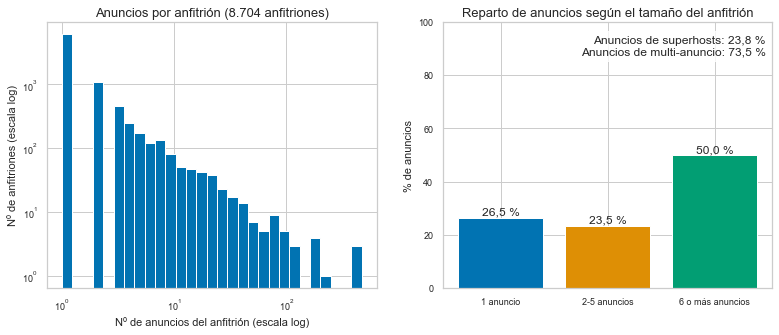

In [33]:
viz.fig_composicion_hosts(df, findings);

In [34]:
h = D["hosts"]
lectura(f"**Lectura.** Hay {fmt.n0(h['n_hosts'])} anfitriones; el {fmt.pct1(h['pct_hosts_un_anuncio'])} tiene un solo "
        f"anuncio, pero el {fmt.pct1(h['pct_anuncios_multianuncio'])} de los anuncios pertenece a cuentas con varios y "
        f"el mayor tiene {fmt.n0(h['anuncios_por_host_max'])}. Es una oferta concentrada: por eso los contrastes del "
        "notebook 02 tienen en cuenta la dependencia entre anuncios del mismo anfitrión.")

**Lectura.** Hay 8.704 anfitriones; el 70,3 % tiene un solo anuncio, pero el 73,5 % de los anuncios pertenece a cuentas con varios y el mayor tiene 469. Es una oferta concentrada: por eso los contrastes del notebook 02 tienen en cuenta la dependencia entre anuncios del mismo anfitrión.

### Tipo de habitación y superhost: tabla cruzada

`crosstab` con `normalize="index"` da el porcentaje de superhosts dentro de cada tipo de habitación. Es la tabla
que después se contrasta con chi-cuadrado.

In [35]:
pd.crosstab(df["tipo_habitacion_agrupado"], df["host_is_superhost"], normalize="index", margins=True).mul(100).round(1)

host_is_superhost,False,True
tipo_habitacion_agrupado,,
Alojamiento entero,73.7,26.3
Habitación privada,81.9,18.1
Otras (compartida + hotel),84.4,15.6
All,76.2,23.8


## 8. Mapas de densidad y de precio

La densidad muestra dónde hay más anuncios; la coropleta, la mediana del precio por barrio (en gris los barrios
con muy pocos anuncios). Las coordenadas están desplazadas por Airbnb unos cientos de metros, así que los mapas
sirven para patrones de zona, no para ubicaciones exactas.

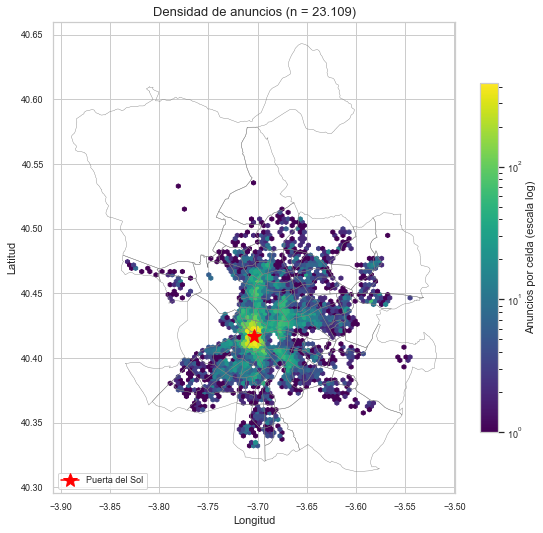

In [36]:
geojson = carga.leer_geojson()
ciudad = config.CIUDADES[config.CIUDAD_POR_DEFECTO]
viz.fig_mapa_densidad(df, geojson, ciudad.centro, ciudad.centro_nombre);

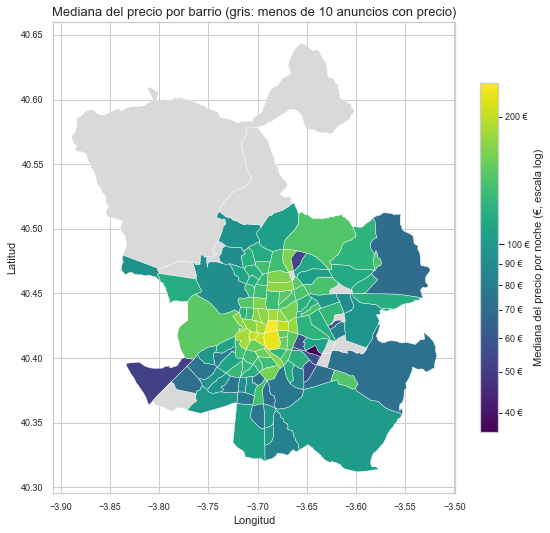

In [37]:
viz.fig_mapa_precio_barrio(df, geojson, config.MIN_N_BARRIO_MAPA);

In [38]:
centro = (df["neighbourhood_group_cleansed"] == ciudad.distrito_referencia).mean() * 100
lectura(f"**Lectura.** El distrito {ciudad.distrito_referencia} concentra el {fmt.pct1(centro)} de los anuncios y la "
        "densidad cae rápidamente al alejarse de la Puerta del Sol. Los barrios de mediana más alta están en el "
        "centro y el norte; la relación con la distancia se cuantifica con la regresión del notebook 02.")

**Lectura.** El distrito Centro concentra el 41,3 % de los anuncios y la densidad cae rápidamente al alejarse de la Puerta del Sol. Los barrios de mediana más alta están en el centro y el norte; la relación con la distancia se cuantifica con la regresión del notebook 02.

## 9. Días no disponibles e ingreso hipotético

`365 − availability_365` cuenta los días **no disponibles en el próximo año**, que incluyen reservas y bloqueos
del anfitrión: no es ocupación. Inside Airbnb estima la ocupación de los **últimos doce meses** a partir de
reseñas. Son ventanas distintas, así que la comparación es orientativa. Ambas medias se calculan sobre las mismas
filas.

In [39]:
oi = D["ocupacion_ingresos"]
pd.Series({k: v for k, v in oi.items() if not isinstance(v, str)}, name="valor").to_frame().round(3)

,valor
n_activos_con_precio,18757.000
n_comparacion_ocupacion,18757.000
no_disponible_media,48.630
no_disponible_mediana,39.726
ocupacion_inside_airbnb_media,31.564
ocupacion_inside_airbnb_mediana,26.301
spearman_ocupacion,0.320
spearman_ocupacion_p,0.000
n_comparacion_ingresos,18757.000
ingreso_hipotetico_mediana,19503.440


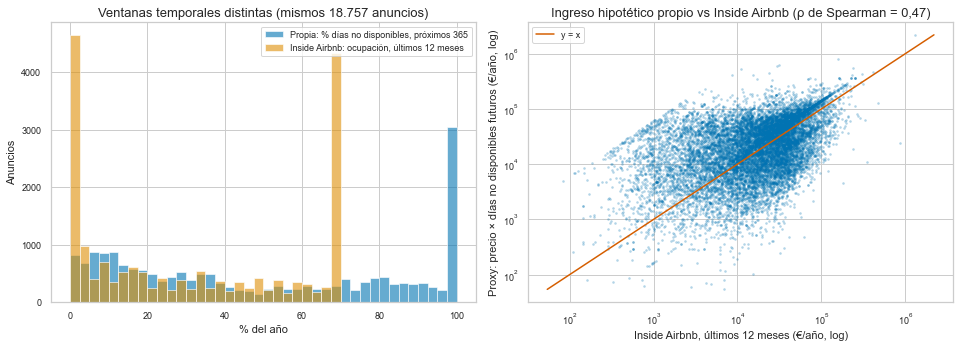

In [40]:
viz.fig_ocupacion_ingresos(df, findings);

In [41]:
lectura(f"**Lectura.** Los días no disponibles promedian un {fmt.pct1(oi['no_disponible_media'])} frente a una "
        f"ocupación estimada por Inside Airbnb del {fmt.pct1(oi['ocupacion_inside_airbnb_media'])} "
        f"(n = {fmt.n0(oi['n_comparacion_ocupacion'])} en ambos casos). La diferencia mezcla bloqueos y ventana "
        f"temporal; la correlación de Spearman del ingreso hipotético con el de Inside Airbnb es "
        f"{fmt.n2(oi['spearman_propio_vs_inside'])}, moderada. Ninguna de las dos es un ingreso observado.")

**Lectura.** Los días no disponibles promedian un 48,6 % frente a una ocupación estimada por Inside Airbnb del 31,6 % (n = 18.757 en ambos casos). La diferencia mezcla bloqueos y ventana temporal; la correlación de Spearman del ingreso hipotético con el de Inside Airbnb es 0,47, moderada. Ninguna de las dos es un ingreso observado.

## 10. Amenities y correlaciones

Los indicadores de amenities se calculan elemento a elemento sobre la lista JSON (así «Dishwasher» no cuenta como
lavadora ni «Pool table» como piscina). La prima de precio de cada amenity es una diferencia bruta de medianas,
que puede reflejar tipo de alojamiento o zona.

In [42]:
pd.DataFrame(D["amenities"])[["nombre", "prevalencia_pct", "mediana_con", "mediana_sin", "prima_pct"]].round(1)

,nombre,prevalencia_pct,mediana_con,mediana_sin,prima_pct
0,Wifi,96.8,151.5,133.0,13.9
1,Cocina,88.7,154.9,123.2,25.7
2,TV,86.7,158.9,76.0,109.1
3,Calefacción,82.0,157.8,120.0,31.5
4,Lavadora,81.2,155.6,135.0,15.3
5,Aire acondicionado,68.1,165.0,109.5,50.7
6,Espacio de trabajo,47.4,148.0,154.2,-4.0
7,Ascensor,46.0,171.0,137.0,24.8
8,Parking (cualquiera),37.6,148.0,153.0,-3.3
9,Llegada autónoma,31.8,169.4,140.0,21.0


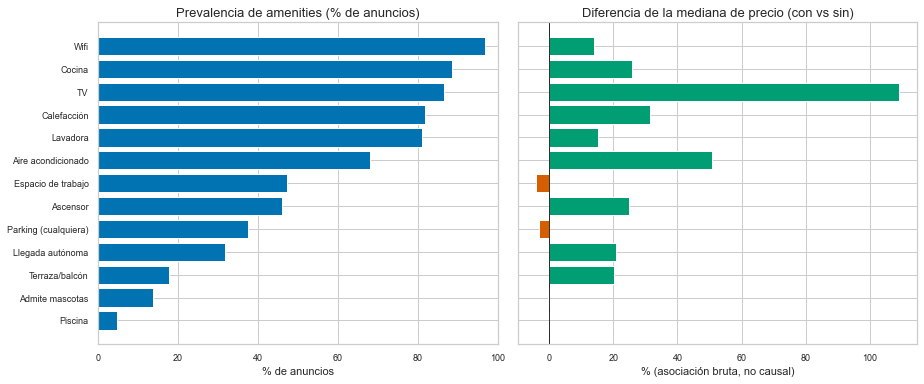

In [43]:
viz.fig_amenities(findings);

In [44]:
am = pd.DataFrame(D["amenities"])
lectura(f"**Lectura.** Las amenities más frecuentes son {', '.join(am['nombre'].str.lower().head(3))} "
        f"(entre {fmt.pct1(am['prevalencia_pct'].iloc[2])} y {fmt.pct1(am['prevalencia_pct'].iloc[0])}). Las primas "
        "brutas más grandes no deben leerse como el valor de añadir esa amenity: la regresión las compara a igualdad "
        "de tipo, capacidad y zona.")

**Lectura.** Las amenities más frecuentes son wifi, cocina, tv (entre 86,7 % y 96,8 %). Las primas brutas más grandes no deben leerse como el valor de añadir esa amenity: la regresión las compara a igualdad de tipo, capacidad y zona.

In [45]:
pd.DataFrame(D["correlaciones"]["con_precio"]).round(3)

,variable,spearman,pearson_log,pearson
0,accommodates,0.597,0.555,0.169
1,beds,0.489,0.259,0.083
2,bedrooms,0.398,0.331,0.118
3,distancia_centro_km,-0.310,-0.243,-0.070
4,n_amenities,0.232,0.212,-0.004
5,bathrooms,0.199,0.135,0.081
6,minimum_nights,-0.191,-0.230,-0.056
7,number_of_reviews,0.137,0.061,-0.017
8,antiguedad_host_anios,0.122,0.111,-0.001
9,reviews_per_month,0.119,0.031,-0.014


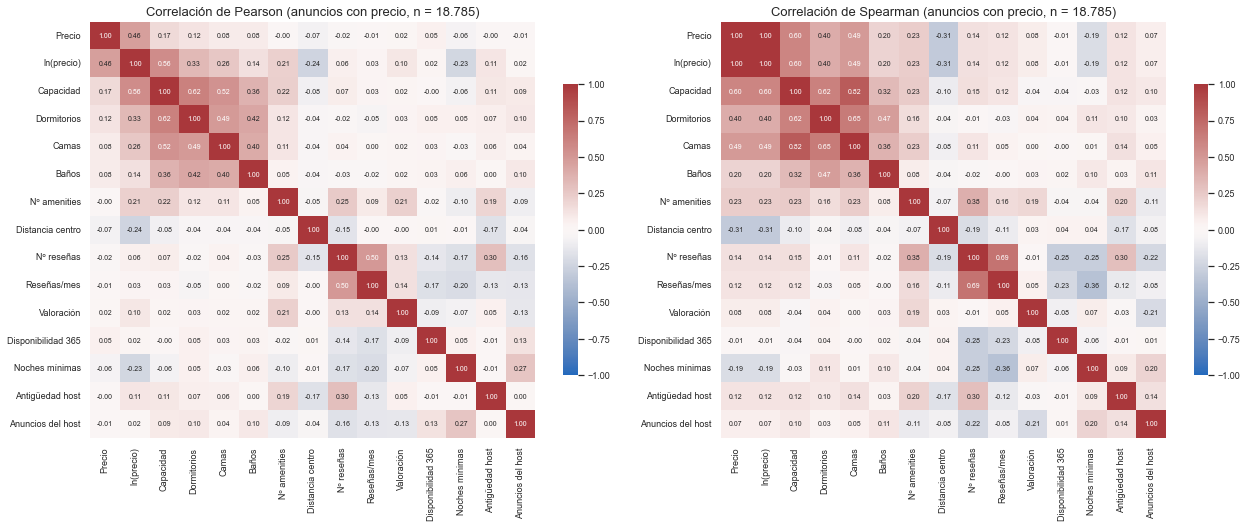

In [46]:
viz.fig_correlaciones(findings);

In [47]:
c0 = D["correlaciones"]["con_precio"][0]
lectura(f"**Lectura.** La variable más correlacionada con el precio es `{c0['variable']}` (ρ de Spearman = "
        f"{fmt.n2(c0['spearman'])}; Pearson sobre el precio en bruto = {fmt.n2(c0['pearson'])}). Pearson en escala "
        "original queda muy por debajo de Spearman porque los precios extremos dominan la covarianza; con este "
        "precio tan asimétrico, rangos o logaritmos son la elección adecuada.")

**Lectura.** La variable más correlacionada con el precio es `accommodates` (ρ de Spearman = 0,60; Pearson sobre el precio en bruto = 0,17). Pearson en escala original queda muy por debajo de Spearman porque los precios extremos dominan la covarianza; con este precio tan asimétrico, rangos o logaritmos son la elección adecuada.

## Conclusión del EDA

El precio por noche es muy asimétrico, con una cola de precios extremos que aleja la media de la mediana, y es el
precio de una cotización concreta: ya incluye descuentos, depende de la duración cotizada (a menudo la estancia
mínima) y de la fecha. Las diferencias más visibles aparecen entre tipos de alojamiento, por capacidad y entre
zonas, con los distritos céntricos en la parte alta; los barrios pequeños tienen medianas inestables.
La oferta está concentrada en cuentas con varios anuncios, lo que obliga a tratar con cuidado la independencia
de las observaciones. Los días no disponibles y el ingreso hipotético son proxies con ventanas temporales
distintas a las de Inside Airbnb, útiles solo como orientación.

Estas observaciones son **hipótesis**: el notebook `02_analisis_estadistico.ipynb` las contrasta formalmente, con
tamaños de efecto, sensibilidad a la dependencia por anfitrión y modelos multivariantes. La interpretación
completa y las limitaciones están en `reports/informe.md`.